In [1]:
#Importing necessary libraries
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import scipy
import netCDF4
import pymannkendall as mk

In [2]:
#Checking whether I downloaded all the files and variables or not

required_vars = {"sf", "tp", "sde"}

problems = []

for n in range(1981, 2026):

    for month, yr in [("dec", n-1), ("jan", n)]:
        fname = f"snow data/{month}{yr}.nc"
        try:
            ds = xr.open_dataset(fname)
            missing = required_vars - set(ds.data_vars)
            if missing:
                problems.append(f"{fname}: missing {missing}")

            for var in required_vars:
                if var in ds:
                    if ds[var].isnull().all():
                        problems.append(f"{fname}: {var} all NaN")

        except Exception as e:
            problems.append(f"{fname}: {e}")

print("\n".join(problems))

if not problems:
    print("All good!")


All good!


In [2]:
# Check for problems in the data
problem_years = []

for n in range(1981, 2026):

    dec1 = xr.open_dataset(f"snow data/Dec{n-1}.nc")
    jan1 = xr.open_dataset(f"snow data/Jan{n}.nc")

    dec = dec1.sel(valid_time=slice(f"{n-1}-12-21", f"{n-1}-12-31"))
    jan = jan1.sel(valid_time=slice(f"{n}-01-01", f"{n}-01-29"))

    try:
        xr.concat([dec, jan], dim="valid_time", join="exact")

    except Exception as e:
        problem_years.append(n)
        print(f"\nProblem in Chillai Kalan {n}:")
        print(type(e).__name__)
        print(e)

print("\n--------------------------------")
print("Problem years:")
print(problem_years)


--------------------------------
Problem years:
[]


In [4]:
#To store snowfall and precipitation data for each year
ds={}
sf={}
pt={}
sde={}

for n in range(1981, 2026):

    dec1 = xr.open_dataset(f"snow data/dec{n-1}.nc")
    jan1 = xr.open_dataset(f"snow data/jan{n}.nc")

    dec = dec1.sel(valid_time=slice(f"{n-1}-12-21", f"{n-1}-12-31"))
    jan = jan1.sel(valid_time=slice(f"{n}-01-01", f"{n}-01-29"))
    ds[n] = xr.concat([dec, jan], dim="valid_time", join="exact")

    sf[n] = ds[n].sf
    pt[n] = ds[n].tp
    sde[n] = ds[n].sde


In [ ]:
#To calucate the total snowfall, precipitation and snow depth for each year

sf_tot = {}
pt_tot = {}
sde_tot = {}
for n in range(1981, 2026):
    sf_tot[n] = (sf[n].sum(dim="valid_time").mean(dim=["latitude","longitude"]).values)
    pt_tot[n] = (pt[n].sum(dim="valid_time").mean(dim=["latitude","longitude"]).values)
    sde_tot[n] = (sde[n].mean(dim="valid_time").mean(dim=["latitude","longitude"]).values)


'plt.figure(figsize=(12,6))\nplt.plot(years, values_sf, marker="o", label="Total Snowfall (m of water equivalent)", color=\'red\')\nplt.xlabel("Year")\nplt.ylabel("Total height of snow(m of water equivalent)")\nplt.title("Annual Snowfall during Chillai Kalan")\nplt.xticks(years, rotation=45)\nplt.grid(True)\nplt.show()\n\nplt.figure(figsize=(12,6))\nplt.plot(years, values_pt, marker="o", label="Total Precipitation (m)")\nplt.xlabel("Year")\nplt.ylabel("Total height of water if it were spread evenly(m)")\nplt.title("Annual Precipitation during Chillai Kalan")\nplt.xticks(years, rotation=45)\nplt.grid(True)\nplt.show()\n\nplt.figure(figsize=(12,6))\nplt.plot(years, values_sde, marker="o", label="Total Snow Depth (m)", color=\'green\')\nplt.xlabel("Year")\nplt.ylabel("Total height of snow accumulated(m)")\nplt.title("Annual Snow Depth During Chillai Kalan")\nplt.xticks(years, rotation=45)\nplt.grid(True)\nplt.legend()\nplt.show()'

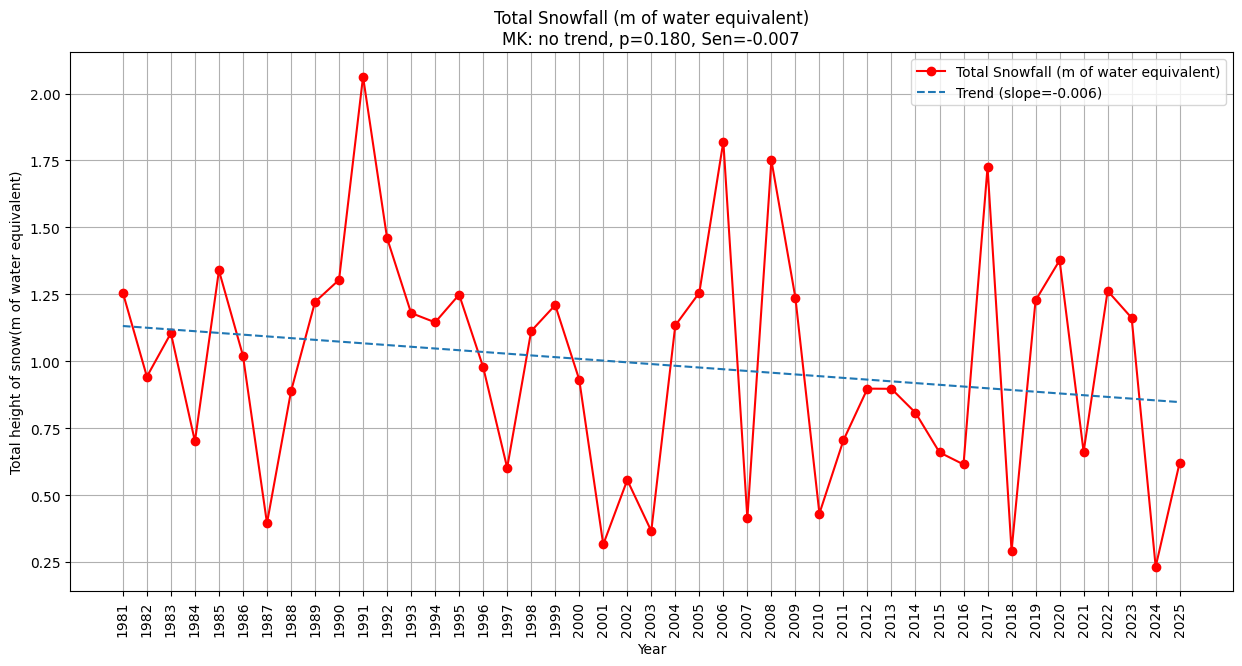

Mann-Kendall test result for Total Snowfall (m of water equivalent):
Trend: no trend
p-value: 0.18018754488317246
Tau: -0.1393939393939394
Sen slope: -0.007161207267978096


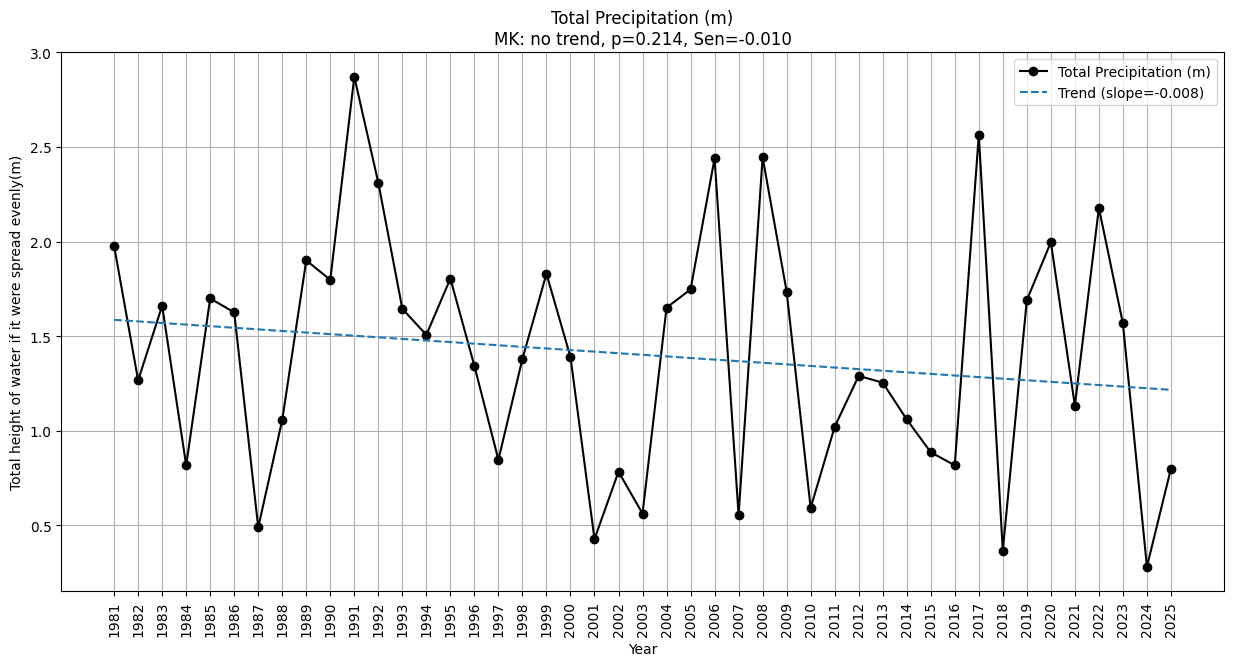

Mann-Kendall test result for Total Precipitation (m):
Trend: no trend
p-value: 0.2141057549143488
Tau: -0.1292929292929293
Sen slope: -0.01049018626684671


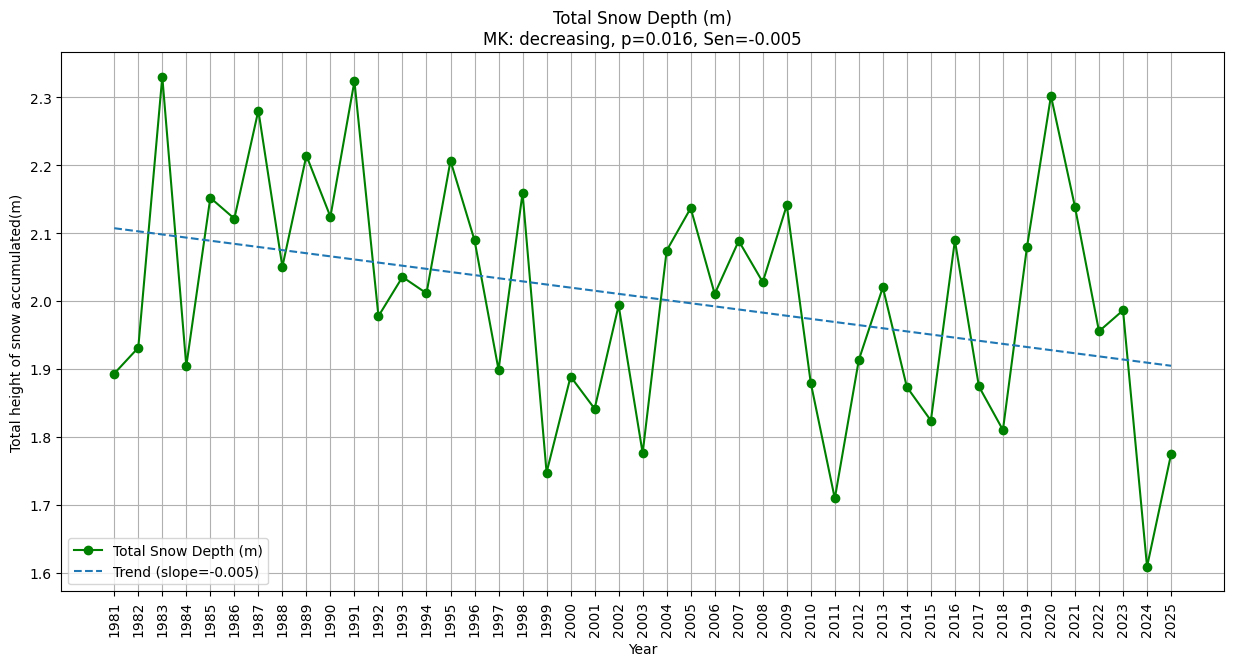

Mann-Kendall test result for Total Snow Depth (m):
Trend: decreasing
p-value: 0.01568202356807058
Tau: -0.2505050505050505
Sen slope: -0.004666225304679265


In [18]:
def plot_trend(variable, title, ylabel, color):
    years = list(variable.keys())
    values = list(variable.values())
    m, b = np.polyfit(years, values, 1)
    trend = m * np.array(years) + b

    result = mk.original_test(values)
    
    plt.figure(figsize=(15,7))
    plt.plot(years, values, marker="o", label=title, color=color)
    plt.plot(years, trend, '--', label=f"Trend (slope={m:.3f})")
    plt.xlabel("Year")
    plt.ylabel(ylabel)
    plt.title(f"{title}\n"f"MK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")
    plt.xticks(years, rotation=90)
    plt.grid(True)
    plt.legend()
    plt.show()

    print(f"Mann-Kendall test result for {title}:")
    print("Trend:", result.trend)
    print("p-value:", result.p)
    print("Tau:", result.Tau)
    print("Sen slope:", result.slope)

plot_trend(sf_tot, "Total Snowfall (m of water equivalent)", "Total height of snow(m of water equivalent)", 'red')
plot_trend(pt_tot, "Total Precipitation (m)", "Total height of water if it were spread evenly(m)", 'black')
plot_trend(sde_tot, "Total Snow Depth (m)", "Total height of snow accumulated(m)", 'green')